In [1]:
import torch
import torch.nn as nn
torch.set_default_dtype(torch.float64)
from collections import OrderedDict
import math
import numpy as np
import sympy as sp
import seaborn as sns
from scipy.interpolate import griddata
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import pandas as pd
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from scipy.stats import qmc
import scipy.io

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
class ChebyKANLayer(nn.Module):
    def __init__(self, input_dim, output_dim, degree):
        super(ChebyKANLayer, self).__init__()
        self.inputdim = input_dim
        self.outdim = output_dim
        self.degree = degree

        self.cheby_coeffs = nn.Parameter(torch.empty(input_dim, output_dim, degree + 1))
        nn.init.xavier_normal_(self.cheby_coeffs)
        self.register_buffer("arange", torch.arange(0, degree + 1, 1))    

    def forward(self, x):
        x = torch.reshape(x, (-1, self.inputdim))
        x = torch.tanh(x)

        cheby = torch.ones(x.shape[0], self.inputdim, self.degree + 1, 
                          device=x.device) #degree若为4，则cheby有5列
        
        if self.degree > 0:
            cheby[:, :, 1] = x
        
        for i in range(2, self.degree + 1):
            cheby[:, :, i] = 2 * x * cheby[:, :, i - 1].clone() - cheby[:, :, i - 2].clone() #T_0(x) = 1；T_1(x) = x；T_{n+1}(x) = 2xT_n(x) - T_{n-1}(x) 对于 n ≥ 1

        y = torch.einsum('bid,iod->bo', cheby, self.cheby_coeffs)  
        y = y.view(-1, self.outdim)
        return y

# 修改DNNLayer，不再需要hidden_dim参数
class DNNLayer(nn.Module):
    def __init__(self, input_dim, output_dim, activation=nn.Tanh):
        super(DNNLayer, self).__init__()
        # 直接使用输入维度作为内部隐藏层维度（从layer_sizes推导）
        self.layer = nn.Sequential(
            nn.Linear(input_dim, input_dim),  # 隐藏层维度 = 输入维度
            activation(),
            nn.Linear(input_dim, output_dim)
        )
        
    def forward(self, x):
        return self.layer(x)

# 混合模型：仅使用layer_sizes定义所有维度
class HybridKAN_DNN(nn.Module):
    def __init__(self, layer_sizes, cheby_degree, lb, ub):
        super(HybridKAN_DNN, self).__init__()
        self.lb = lb
        self.ub = ub
        self.layers = nn.ModuleList()
        
        # 完全通过layer_sizes定义各层维度
        for i in range(len(layer_sizes) - 1):
            if i % 2 == 0:  # 偶数索引：ChebyKAN层
                self.layers.append(ChebyKANLayer(
                    input_dim=layer_sizes[i],
                    output_dim=layer_sizes[i+1],
                    degree=cheby_degree
                ))
            else:  # 奇数索引：DNN层（内部维度自动从layer_sizes[i]获取）
                self.layers.append(DNNLayer(
                    input_dim=layer_sizes[i],
                    output_dim=layer_sizes[i+1]
                ))
    
    def forward(self, x):
        out = 2 * (x - self.lb) / (self.ub - self.lb) - 1
        for layer in self.layers:
            out = layer(out)
        return out

In [4]:
# the physics-guided neural network
class PIKDN(nn.Module):
    def __init__(self, X_ub,X_lb,X_ic,X_res,u_ic,v_ic,alpha,beta,gamma,layers, degree, lb, ub):
        super(PIKDN, self).__init__()
        # boundary conditions
        
        self.z_ub = torch.tensor(X_ub[:, 0:1], requires_grad=True).double().to(device)
        self.t_ub = torch.tensor(X_ub[:, 1:2], requires_grad=True).double().to(device)

        self.z_lb = torch.tensor(X_lb[:, 0:1], requires_grad=True).double().to(device)
        self.t_lb = torch.tensor(X_lb[:, 1:2], requires_grad=True).double().to(device)

        self.z_ic = torch.tensor(X_ic[:, 0:1], requires_grad=True).double().to(device)
        self.t_ic = torch.tensor(X_ic[:, 1:2], requires_grad=True).double().to(device)
        self.u_ic = torch.tensor(u_ic).double().to(device)
        self.v_ic = torch.tensor(v_ic).double().to(device)
        self.u_ub_e = torch.tensor(u_ub_e).double().to(device)
        self.v_ub_e = torch.tensor(v_ub_e).double().to(device)
        self.ux_ub_e = torch.tensor(ux_ub_e).double().to(device)
        self.vx_ub_e = torch.tensor(vx_ub_e).double().to(device)
        self.u_lb_e = torch.tensor(u_lb_e).double().to(device)
        self.v_lb_e = torch.tensor(v_lb_e).double().to(device)
        self.ux_lb_e = torch.tensor(ux_lb_e).double().to(device)
        self.vx_lb_e = torch.tensor(vx_lb_e).double().to(device)

        self.z_res = torch.tensor(X_res[:, 0:1], requires_grad=True).double().to(device)
        self.t_res = torch.tensor(X_res[:, 1:2], requires_grad=True).double().to(device)

        self.alpha = torch.tensor(alpha).double().to(device)
        self.beta = torch.tensor(beta).double().to(device)
        self.gamma = torch.tensor(gamma).double().to(device)

        self.lb = torch.tensor(lb).double().to(device)  # 归一化下界
        self.ub = torch.tensor(ub).double().to(device)  # 归一

        self.layers = layers
        
        self.net = HybridKAN_DNN(layers, degree, self.lb, self.ub).to(device)

        self.iter = 0

        self.optimizer1 = torch.optim.Adam(self.net.parameters(),lr=1e-3)

        self.optimizer2 = torch.optim.LBFGS(
            self.net.parameters(), 
            lr=1.0, #步长缩放因子，用于控制拟牛顿算法中搜索的步长
            max_iter=40000, #最大迭代次数
            max_eval=40000, #函数和梯度最大评估次数
            history_size=50, #存储和更新历史信息的缓存大小
            tolerance_grad=1e-7, #表示梯度的容差，即梯度的变化小于该容差时，算法将终止
            tolerance_change=1.0 * np.finfo(float).eps, #表示优化变化的容差，即参数变化量的绝对值小于该容差时，算法将终止
            line_search_fn="strong_wolfe" #can be "strong_wolfe"
        )

        self.loss_history = {
            'total': [],
            'residual': [],
            'ic': [],
            'b': []
        }
        
    def net_h(self, z, t):  
        H = self.net(torch.cat([z, t], dim=1))
        u = H[:, 0:1]
        v = H[:, 1:2]
        return u,v
        
    def gradient(self, y, x):
        return torch.autograd.grad(y, x, grad_outputs=torch.ones_like(y), retain_graph=True, create_graph=True)[0]
    
    def net_b(self, z, t):

        u,v = self.net_h(z, t)
        u_z = self.gradient(u, z)
        v_z = self.gradient(v, z)

        return u, v, u_z, v_z            
    
    def net_ic(self, z, t):

        u, v = self.net_h(z, t)

        return u, v      
    
    def net_f(self, z, t):

        u,v = self.net_h(z, t)
        v_t = self.gradient(v, t)
        v_z = self.gradient(v, z)

        u_t = self.gradient(u, t)
        u_z = self.gradient(u, z)
        u_zz = self.gradient(u_z, z)
        u_zzz = self.gradient(u_zz, z)

        f1 = u_t - v_z
        f2 = v_t + self.alpha * u_z + self.beta * (2*u*u_z) + self.gamma * u_zzz

        return f1, f2

    def loss_func(self):

        self.optimizer1.zero_grad()
        self.optimizer2.zero_grad()

        u_ic_pred, v_ic_pred = self.net_ic(self.z_ic, self.t_ic)

        u_ub_pred, v_ub_pred, u_z_ub_pred, v_z_ub_pred = self.net_b(self.z_ub, self.t_ub)

        u_lb_pred, v_lb_pred, u_z_lb_pred, v_z_lb_pred = self.net_b(self.z_lb, self.t_lb)

        f1_res_pred, f2_res_pred = self.net_f(self.z_res, self.t_res)

        loss_res1 = torch.mean(f1_res_pred**2)
        loss_res2 = torch.mean(f2_res_pred**2)
        loss_res = loss_res1 + loss_res2
        loss_ic1 = torch.mean((u_ic_pred - self.u_ic)**2)
        loss_ic2 = torch.mean((v_ic_pred - self.v_ic)**2)
        loss_b1 = torch.mean((u_ub_pred - self.u_ub_e)**2)
        loss_b2 = torch.mean((v_ub_pred - self.v_ub_e)**2)
        loss_b3 = torch.mean((u_z_ub_pred - self.ux_ub_e)**2)
        loss_b4 = torch.mean((v_z_ub_pred - self.vx_ub_e)**2)
        loss_b5 = torch.mean((u_lb_pred - self.u_lb_e)**2)
        loss_b6 = torch.mean((v_lb_pred - self.v_lb_e)**2)
        loss_b7 = torch.mean((u_z_lb_pred - self.ux_lb_e)**2)
        loss_b8 = torch.mean((v_z_lb_pred - self.vx_lb_e)**2)

        loss_ic = loss_ic1 + loss_ic2
        loss_b = loss_b1 + loss_b2 + loss_b3 + loss_b4 + loss_b5 + loss_b6 + loss_b7 + loss_b8

        loss = loss_res + loss_ic1 + loss_ic2 + loss_b

        # self.loss_history['total'].append(loss.item())
        # self.loss_history['residual'].append(loss_res.item())
        # self.loss_history['ic'].append(loss_ic.item())
        # self.loss_history['b'].append(loss_b.item())
        
        loss.backward()
        self.iter += 1
        if self.iter % 100 == 0:
            self.loss_history['total'].append(loss.item())
            self.loss_history['residual'].append(loss_res.item())
            self.loss_history['ic'].append(loss_ic.item())
            self.loss_history['b'].append(loss_b.item())
            print(
                'Iter %d, Loss: %.5e, Loss_res: %.5e, Loss_ic1: %.5e, Loss_ic2: %.5e, Loss_b1: %.5e, Loss_b2: %.5e, Loss_b3: %.5e, Loss_b4: %.5e' % 
                (   self.iter, 
                    loss.item(), 
                    loss_res.item(), 
                    loss_ic1.item(),
                    loss_ic2.item(), 
                    loss_b1.item(),
                    loss_b2.item(),
                    loss_b3.item(),
                    loss_b4.item()
                )
            )

        return loss
    
    def train(self):
        self.net.train()
        import time
        t_start = time.time()
        print("采用Adam优化器")
        for i in range(20000):
            self.optimizer1.step(self.loss_func)
        # 然后运行lbfgs优化器
        print("采用L-BFGS优化器")
        self.optimizer2.step(self.loss_func)
        print('Total training time: %.2f h (%.0f min)' % ((time.time()-t_start)/3600, (time.time()-t_start)/60))
 
            
    def predict(self, X):
        
        z = torch.tensor(X[:, 0:1], requires_grad=True).double().to(device)
        t = torch.tensor(X[:, 1:2], requires_grad=True).double().to(device)

        self.net.eval()
        u,v = self.net_h(z, t)
        u = u.detach().cpu().numpy()
        v = v.detach().cpu().numpy()

        return u, v

In [5]:
# reproducibility: random seed 1 (covers LHS sampling and network init)
import random
seed = 4
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# alpha = -1
# beta = -3
# gamma = -1

# N_res = 1000
# N_b = 100
# N_ic = 100

# x = np.linspace(-15, 15, 201)
# t = np.linspace(0, 5, 201) 
# x_mesh, t_mesh = np.meshgrid(x, t)

# X = np.hstack((x_mesh.flatten()[:,None], t_mesh.flatten()[:,None]))

# lb = X.min(0) #下界x'QxQ
# ub = X.max(0)  #上界 

# def lhs(n, size):
#     """生成n维拉丁超立方采样，返回size个样本点"""
#     sampler = qmc.LatinHypercube(d=n)
#     return sampler.random(n=size)

# # 使用简洁形式进行采样（与你要求的形式一致）
# X_res = lb + (ub - lb) * lhs(2, N_res)  # 2维残差点采样

# t_samples = lb[1] + (ub[1] - lb[1]) * lhs(1, N_b)  # 时间t的采样：[N_b, 1]

# # 上边界点（x=ub[0]，与下边界对称）
# X_ub = np.hstack((ub[0] * np.ones((N_b, 1)),t_samples))
# X_lb = np.hstack((lb[0] * np.ones((N_b, 1)),t_samples))

# X_ic = np.hstack((lb[0] + (ub[0] - lb[0]) * lhs(1, N_ic), 
#                   lb[1] * np.ones((N_ic, 1))))  # 初始条件点

In [6]:
alpha = -1
beta = -3
gamma = -1

x = np.linspace(-15, 15, 301)
t = np.linspace(0, 5, 201) 
x_mesh, t_mesh = np.meshgrid(x, t)

X = np.hstack((x_mesh.flatten()[:,None], t_mesh.flatten()[:,None]))

lb = X.min(0) #下界x'QxQ
ub = X.max(0)  #上界 

df_h = np.load("/kaggle/input/datasets/ouyangyalin0312/bq-soliton-residual-0-15-10000points/residual_10000.npz")
X_res = df_h['X_res']
X_ub = df_h['X_ub']
X_lb = df_h['X_lb']
X_ic = df_h['X_ic']

In [7]:
def func_u(X):
    x, t = X[:, 0:1], X[:, 1:2]
    zeta = 1/6
    y1 = 0
    y2 = 0
    y3 = 2
    k1 = 1
    k2 = 1
    k3 = 5/4
    varsigma1 = -2
    varsigma2 = 4
    varsigma3 = -4

    u=-alpha/(2*beta) + zeta + 6*gamma*(-k1**2*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - k2**2*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - k3**2*np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) + (k1 + k2)**2*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (k1 + k3)**2*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k2 + k3)**2*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k1 + k2 + k3)**2*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) - (-k1*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - k2*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - k3*np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) + (k1 + k2)*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (k1 + k3)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k2 + k3)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k1 + k2 + k3)*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)))**2/((2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) + (2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) - 1))/(beta*((2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) + (2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) - 1))
    return u

def func_v(X):
    x, t = X[:, 0:1], X[:, 1:2]
    zeta = 1/6
    y1 = 0
    y2 = 0
    y3 = 2
    k1 = 1
    k2 = 1
    k3 = 5/4
    varsigma1 = -2
    varsigma2 = 4
    varsigma3 = -4

    v=6*gamma*(-k1**2*np.sqrt(-2*beta*zeta - gamma*k1**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) + k2**2*np.sqrt(-2*beta*zeta - gamma*k2**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - k3**2*np.sqrt(-2*beta*zeta - gamma*k3**2)*np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) + (k1 + k2)*(k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (k1 + k3)*(k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - (k2 + k3)*(k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k1 + k2 + k3)*(k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) - (-k1*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - k2*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - k3*np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) + (k1 + k2)*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (k1 + k3)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k2 + k3)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k1 + k2 + k3)*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)))*(-k1*np.sqrt(-2*beta*zeta - gamma*k1**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2)*np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))*(2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)))/((2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) + (2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) - 1))/(beta*((2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma2 + varsigma3)/((2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)) + (2*beta*zeta*(k1 - k2)**2 + gamma*(k1 - k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) - k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma1 + varsigma2)/(2*beta*zeta*(k1 + k2)**2 + gamma*(k1 + k2)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k2*np.sqrt(-2*beta*zeta - gamma*k2**2))**2) + (2*beta*zeta*(k1 - k3)**2 + gamma*(k1 - k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma1 + varsigma3)/(2*beta*zeta*(k1 + k3)**2 + gamma*(k1 + k3)**4 + (k1*np.sqrt(-2*beta*zeta - gamma*k1**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) + (2*beta*zeta*(k2 - k3)**2 + gamma*(k2 - k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) + k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2)*np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma2 + varsigma3)/(2*beta*zeta*(k2 + k3)**2 + gamma*(k2 + k3)**4 + (k2*np.sqrt(-2*beta*zeta - gamma*k2**2) - k3*np.sqrt(-2*beta*zeta - gamma*k3**2))**2) - np.exp(k1*t*np.sqrt(-2*beta*zeta - gamma*k1**2) + k1*(x + y1) + varsigma1) - np.exp(-k2*t*np.sqrt(-2*beta*zeta - gamma*k2**2) + k2*(x + y2) + varsigma2) - np.exp(k3*t*np.sqrt(-2*beta*zeta - gamma*k3**2) + k3*(x + y3) + varsigma3) - 1))
    return v

u_ic = func_u(X_ic)
v_ic = func_v(X_ic)

# Dirichlet+Neumann boundary data from the exact solution (replaces periodic identification)
eps_b = 1e-5
u_ub_e  = func_u(X_ub);  v_ub_e  = func_v(X_ub)
u_lb_e  = func_u(X_lb);  v_lb_e  = func_v(X_lb)
ux_ub_e = (func_u(X_ub + [eps_b, 0]) - func_u(X_ub - [eps_b, 0])) / (2*eps_b)
vx_ub_e = (func_v(X_ub + [eps_b, 0]) - func_v(X_ub - [eps_b, 0])) / (2*eps_b)
ux_lb_e = (func_u(X_lb + [eps_b, 0]) - func_u(X_lb - [eps_b, 0])) / (2*eps_b)
vx_lb_e = (func_v(X_lb + [eps_b, 0]) - func_v(X_lb - [eps_b, 0])) / (2*eps_b)


In [8]:
degree = 4
layers = [2,16,45,16,45,16,45,2]
 
model = PIKDN(X_ub, X_lb, X_ic, X_res, u_ic, v_ic, alpha, beta, gamma, layers, degree, lb, ub)

In [9]:
model

PIKDN(
  (net): HybridKAN_DNN(
    (layers): ModuleList(
      (0): ChebyKANLayer()
      (1): DNNLayer(
        (layer): Sequential(
          (0): Linear(in_features=16, out_features=16, bias=True)
          (1): Tanh()
          (2): Linear(in_features=16, out_features=45, bias=True)
        )
      )
      (2): ChebyKANLayer()
      (3): DNNLayer(
        (layer): Sequential(
          (0): Linear(in_features=16, out_features=16, bias=True)
          (1): Tanh()
          (2): Linear(in_features=16, out_features=45, bias=True)
        )
      )
      (4): ChebyKANLayer()
      (5): DNNLayer(
        (layer): Sequential(
          (0): Linear(in_features=16, out_features=16, bias=True)
          (1): Tanh()
          (2): Linear(in_features=16, out_features=45, bias=True)
        )
      )
      (6): ChebyKANLayer()
    )
  )
)

In [10]:
def count_parameters(model):
    """计算模型中可训练参数的总个数"""
    total_params = 0
    for param in model.parameters():
        # 累加每个参数张量的元素数量
        total_params += param.numel()
    return total_params

param_count = count_parameters(model)
print(f"模型可训练参数总个数: {param_count:,}")  # 使用逗号作为千位分隔符

模型可训练参数总个数: 10,921


In [11]:
model.train()

采用Adam优化器
Iter 100, Loss: 6.10949e-02, Loss_res: 1.12571e-02, Loss_ic1: 1.54939e-02, Loss_ic2: 3.27995e-02, Loss_b1: 4.30935e-04, Loss_b2: 3.55315e-04, Loss_b3: 7.85260e-05, Loss_b4: 2.00489e-05
Iter 200, Loss: 4.29235e-02, Loss_res: 1.14826e-02, Loss_ic1: 1.21753e-02, Loss_ic2: 1.88165e-02, Loss_b1: 2.38368e-04, Loss_b2: 6.05294e-05, Loss_b3: 5.43943e-05, Loss_b4: 3.64502e-05
Iter 300, Loss: 2.48256e-02, Loss_res: 9.12430e-03, Loss_ic1: 7.47538e-03, Loss_ic2: 8.04932e-03, Loss_b1: 4.49324e-05, Loss_b2: 3.88667e-05, Loss_b3: 2.01752e-05, Loss_b4: 6.56219e-06
Iter 400, Loss: 1.21816e-02, Loss_res: 7.85453e-03, Loss_ic1: 2.12489e-03, Loss_ic2: 2.06096e-03, Loss_b1: 7.42631e-05, Loss_b2: 1.02891e-05, Loss_b3: 5.22796e-07, Loss_b4: 1.02958e-05
Iter 500, Loss: 7.90393e-03, Loss_res: 6.58973e-03, Loss_ic1: 5.40475e-04, Loss_ic2: 7.24803e-04, Loss_b1: 8.13341e-06, Loss_b2: 3.60956e-06, Loss_b3: 1.00252e-06, Loss_b4: 1.24071e-05
Iter 600, Loss: 6.25439e-03, Loss_res: 5.54229e-03, Loss_ic1: 2.8

In [12]:
all_states1 = {"model": model.net.state_dict(), "LBFGS": model.optimizer2.state_dict()}
torch.save(obj=all_states1, f="all_states1.pth")

In [13]:
u_p,v_p = model.predict(X)
u_true = func_u(X)
v_true = func_v(X)

In [14]:
L2 = np.linalg.norm(u_p.flatten() - u_true.flatten())/np.linalg.norm(u_true.flatten())

print (L2)

0.0006309247328309133


In [15]:
L2 = np.linalg.norm(v_p.flatten() - v_true.flatten())/np.linalg.norm(v_true.flatten())

print (L2)

0.0006996411997271348


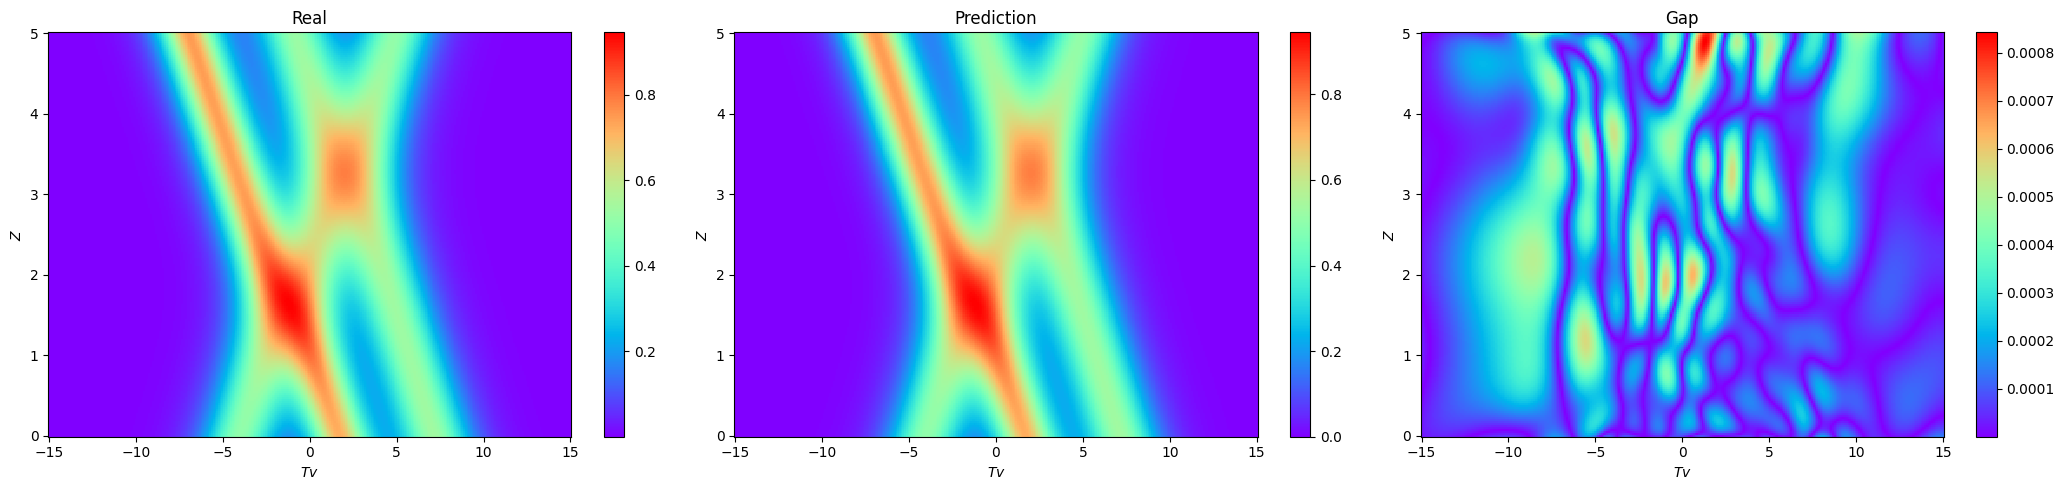

In [16]:
H_pred = griddata(X, u_p.flatten(), (x_mesh,t_mesh), method='cubic')
H_True = griddata(X, u_true.flatten(), (x_mesh,t_mesh), method='cubic')

def plot_all(T, X, H_True, H_pred):
    fig, axes = plt.subplots(1, 3, figsize=(21, 5))  # 创建1行3列的子图布局
    
    # 真实值图
    im0 = axes[0].pcolor(T, X, H_True, cmap='rainbow')
    axes[0].set_xlabel('$Tv$')
    axes[0].set_ylabel('$Z$')
    axes[0].set_title('Real')
    plt.colorbar(im0, ax=axes[0])
    
    # 预测值图
    im1 = axes[1].pcolor(T, X, H_pred, cmap='rainbow')
    axes[1].set_xlabel('$Tv$')
    axes[1].set_ylabel('$Z$')
    axes[1].set_title('Prediction')
    plt.colorbar(im1, ax=axes[1])
    
    # 差距图
    im2 = axes[2].pcolor(T, X, np.abs(H_True - H_pred), cmap='rainbow')
    axes[2].set_xlabel('$Tv$')
    axes[2].set_ylabel('$Z$')
    axes[2].set_title('Gap')
    plt.colorbar(im2, ax=axes[2])
    
    plt.tight_layout()
    plt.show()

# 调用函数绘制并排的三幅图
plot_all(x_mesh, t_mesh, H_True, H_pred)

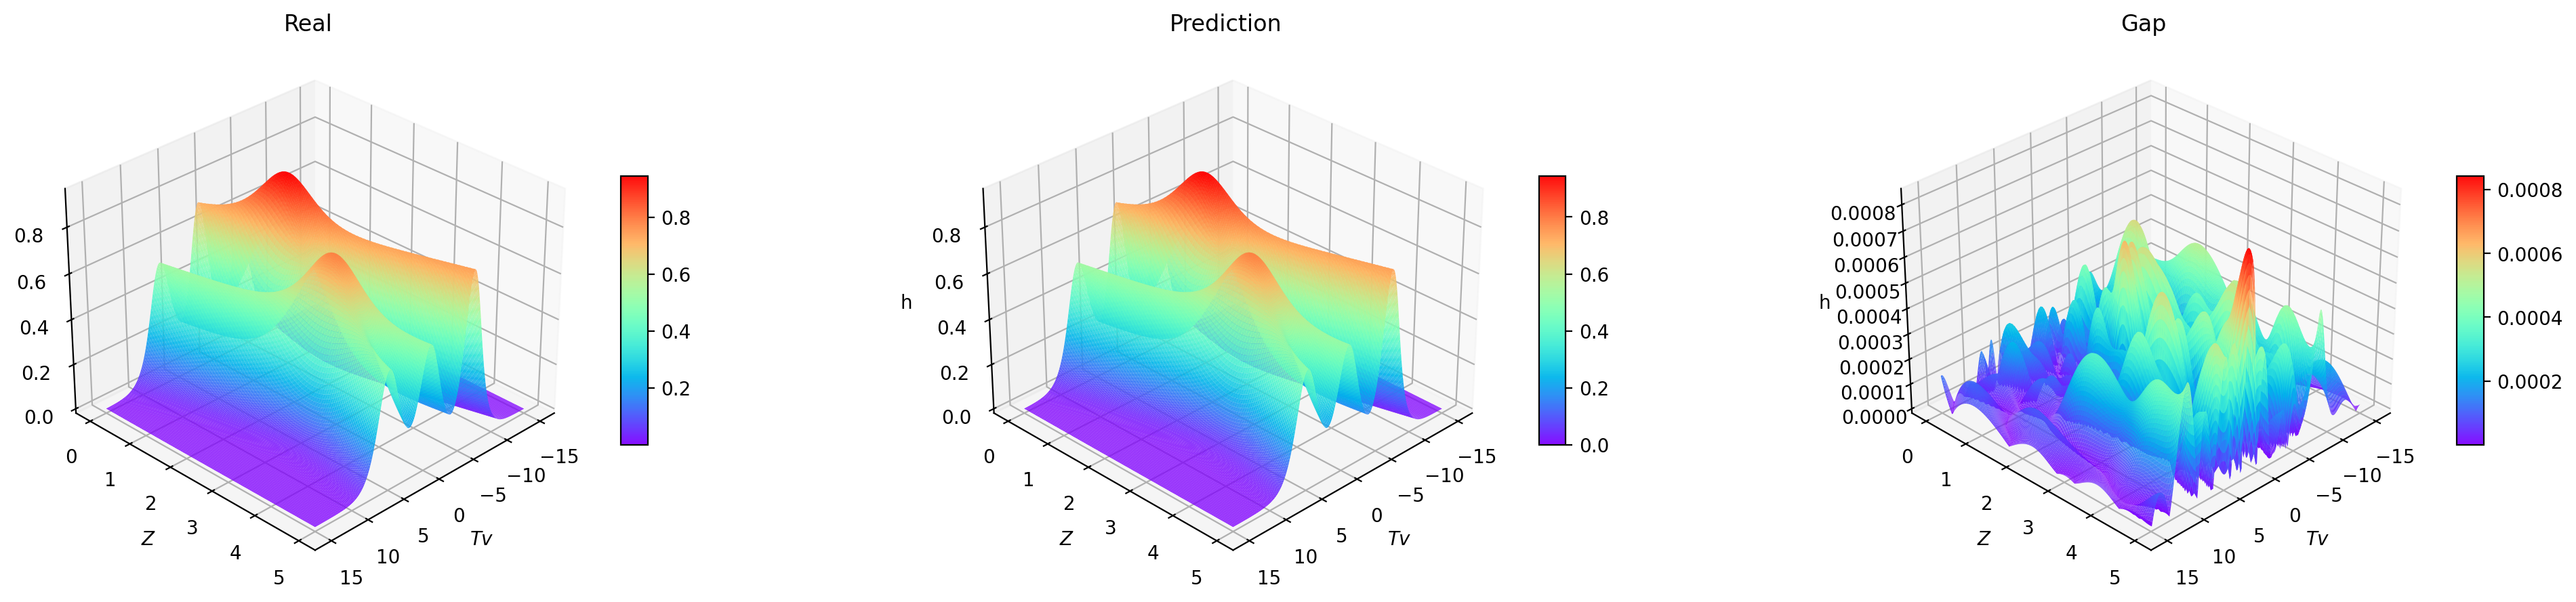

In [17]:
def plot_all_3d(T, X, H_True, H_pred, smooth_factor=1.0, dpi=150):
    """
    绘制对比3D图像（真实值、预测值和差值），并优化显示效果
    
    参数:
    - smooth_factor: 控制插值平滑程度的因子
    - dpi: 图像分辨率
    """
    # 创建更高分辨率的图形
    fig = plt.figure(figsize=(21, 5), dpi=dpi)
    
    # 定义共享的颜色映射和视角
    cmap = plt.get_cmap('rainbow')  # 
    #cmap = cm.get_cmap('viridis')  # 使用更现代的颜色映射
    elev, azim = 30, 45  # 定义共享的视角
    
    # 创建更平滑的网格数据（可选）
    if smooth_factor > 1:
        from scipy.ndimage import gaussian_filter
        H_True_smooth = gaussian_filter(H_True, sigma=smooth_factor)
        H_pred_smooth = gaussian_filter(H_pred, sigma=smooth_factor)
    else:
        H_True_smooth = H_True
        H_pred_smooth = H_pred
    
    # 计算误差
    error = np.abs(H_True - H_pred)
    
    # 定义绘图函数，减少代码重复
    def plot_surface(ax, X, Y, Z, title, cmap=cmap):
        surf = ax.plot_surface(X, Y, Z, cmap=cmap, 
                              linewidth=0, antialiased=True,
                              rstride=1, cstride=1,
                              alpha=0.95)
        ax.set_xlabel('$Tv$')
        ax.set_ylabel('$Z$')
        ax.set_zlabel('h')
        ax.set_title(title)
        ax.view_init(elev=elev, azim=azim)
        fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.05)
        # 添加网格线增强深度感
        ax.grid(True, linestyle='-', alpha=0.3)
        return surf
    
    # 真实值3D图
    ax0 = fig.add_subplot(131, projection='3d')
    plot_surface(ax0, T, X, H_True_smooth, 'Real')
    
    # 预测值3D图
    ax1 = fig.add_subplot(132, projection='3d')
    plot_surface(ax1, T, X, H_pred_smooth, 'Prediction')
    
    # 差距3D图
    ax2 = fig.add_subplot(133, projection='3d')
    # 使用专门的误差颜色映射
    #error_cmap = cm.get_cmap('Reds')
    plot_surface(ax2, T, X, error, 'Gap')
    
    # 调整布局，确保有足够的空间显示标签和颜色条
    plt.tight_layout(pad=3.0)
    plt.show()

# 示例调用
plot_all_3d(x_mesh, t_mesh, H_True, H_pred, smooth_factor=1.2, dpi=200)

In [18]:
data = {
    'x': x_mesh.flatten()[:, None],       # x网格数据（竖排）
    't': t_mesh.flatten()[:, None],       # t网格数据（竖排）
    'h_true': u_true.flatten()[:, None],  # u真实值（竖排）
    'g_true': v_true.flatten()[:, None],  # v真实值（竖排）
    'h_pred': u_p.flatten()[:, None],     # u预测值（竖排）
    'g_pred': v_p.flatten()[:, None]      # v预测值（竖排）
}

# 保存到单个MAT文件
scipy.io.savemat('PIKDNall_data.mat', data)

In [19]:
# scipy.io.savemat('3wavedata_PIKAN/x.mat', {'array': x_mesh.flatten()[:, None]})
# scipy.io.savemat('3wavedata_PIKAN/t.mat', {'array': t_mesh.flatten()[:, None]})
# scipy.io.savemat('3wavedata_PIKAN/h_true.mat', {'array': u_true.flatten()[:, None]})
# scipy.io.savemat('3wavedata_PIKAN/g_true.mat', {'array': v_true.flatten()[:, None]})
# scipy.io.savemat('3wavedata_PIKAN/h_pred.mat', {'array': u_p.flatten()[:, None]})
# scipy.io.savemat('3wavedata_PIKAN/g_pred.mat', {'array': v_p.flatten()[:, None]})

In [20]:
loss_total = model.loss_history['total']
loss_residual = model.loss_history['residual']
loss_ic = model.loss_history['ic']
loss_b = model.loss_history['b']

In [21]:
num_iterations = len(loss_total)  # 损失记录的总数量（即总迭代次数）
iter_steps = list(range(100, 100 + num_iterations * 100, 100))

In [22]:
# 3. 将数据转换为竖排（列向量）：通过reshape(-1, 1)实现，形状变为(n, 1)
iter_steps_col = np.array(iter_steps).reshape(-1, 1)       # 竖排迭代步数
loss_total_col = np.array(loss_total).reshape(-1, 1)       # 竖排总损失
loss_residual_col = np.array(loss_residual).reshape(-1, 1) # 竖排残差损失
loss_ic_col = np.array(loss_ic).reshape(-1, 1)             # 竖排初始条件损失
loss_b_col = np.array(loss_b).reshape(-1, 1)               # 竖排边界条件损失

# 4. 整理并保存为mat文件（此时所有数据均为列向量）
data_loss = {
    'iter_steps': iter_steps_col,
    'loss_total': loss_total_col,
    'loss_residual': loss_residual_col,
    'loss_ic': loss_ic_col,
    'loss_b': loss_b_col
}

scipy.io.savemat('PIKDNloss_history.mat', data_loss)
print("竖排格式的损失函数和迭代步数已保存为 loss_history.mat")

竖排格式的损失函数和迭代步数已保存为 loss_history.mat
